# Function 2 — Week 10 owner-only and full-cohort GP models

Compare the established Gaussian processes on the same official targets. The saved owner-only suggestion is replayed at its exact input. The full-cohort version searches again after fitting the current pool using the weekly UCB weight.

[Observation review](observation_review.ipynb) · [Week 10 review](../../../../results/week-10-review.md)

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import sys

from IPython.display import display
import numpy as np
import pandas as pd

ANALYSIS_DIR = Path.cwd().resolve()
ROOT = next(path for path in ANALYSIS_DIR.parents if (path / "run-python.ps1").is_file())
EXPECTED_KERNEL = ROOT / ".venv" / ("Scripts/python.exe" if sys.platform == "win32" else "bin/python")
if Path(sys.executable).resolve() != EXPECTED_KERNEL.resolve():
    raise RuntimeError(f"Select the Capstone kernel: {EXPECTED_KERNEL}")
STAGE = ROOT / "stage-2-bbo"
SHARED = STAGE / "notebooks/Shared"
if str(SHARED) not in sys.path:
    sys.path.insert(0, str(SHARED))
from cohort_review_helpers import load_dated_cohort_review


In [2]:
FUNCTION_NUMBER = 2
INPUT_COLUMNS = ['x1', 'x2']
EXPECTED_ROUND_COUNTS = {0: 10, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1}
HEIGHT_SCALE = None
TARGET_LABEL = 'output y'
SELECTION_METRIC = 'LOO RMSE'
MODEL_SETTINGS = {'noise_fraction': 0.1, 'ridge_alpha': 1.0, 'kernel_ridge_alpha': 0.1, 'kernel_ridge_gamma': 1.0, 'length_scale': 0.3, 'length_scale_bounds': (0.03, 2.0), 'amplitude': 1.0, 'amplitude_bounds': (0.01, 100.0), 'optimiser_restarts': 3, 'seed': 42}
FIXED_MODEL_SETTINGS = None
FEATURE_SETS = {'GP: x1 only': (0,)}
GP_NAMES = ['Gaussian process', 'GP: x1 only', 'GP: separate length scales']
EXPLORATION_WEIGHT = 1.96
EXPLORATION_WEIGHTS = (0.0, 1.0, 1.96, 3.0)
MIN_QUERY_DISTANCE = 0.0
SEARCH_SETTINGS = {'broad_power': 14, 'broad_seed': 42, 'local_power': 12, 'local_seed': 43, 'local_radius': 0.15, 'precision': 6, 'include_corners': True}

In [3]:
OFFICIAL_DIR = ANALYSIS_DIR.parent / "official" if FUNCTION_NUMBER <= 4 else ANALYSIS_DIR.parent
OFFICIAL_CSV = OFFICIAL_DIR / "observations.csv"
SNAPSHOT = STAGE / "data/cohort/2026-11-25"
FIGURES = ANALYSIS_DIR / "figures"
FIGURES.mkdir(exist_ok=True)
review, intake = load_dated_cohort_review(SNAPSHOT, OFFICIAL_CSV, function=FUNCTION_NUMBER,
    input_columns=INPUT_COLUMNS, expected_round_counts=EXPECTED_ROUND_COUNTS)
official_data = review["own_data"]
peer_data = review["data"].loc[review["peer_mask"]]
display(pd.Series({"Official observations": len(official_data), "Published peer returns": len(peer_data),
    "New peer returns since 23 November": intake["new_peer"], "Total observations": len(review["data"])}))


Official observations                 19
Published peer returns                31
New peer returns since 23 November     4
Total observations                    50
dtype: int64

## Compare on the same official targets

Each fold withholds an official target and, in the cohort fit, peer returns at the same six-decimal input.

In [4]:
from model_helpers import make_models
from model_review_helpers import make_regression_models
from prediction_review_helpers import compare_full_cohort_gp
from model_review_plots import plot_paired_cohort_profiles

available = make_regression_models(len(INPUT_COLUMNS), feature_sets=FEATURE_SETS, **MODEL_SETTINGS)
if FUNCTION_NUMBER == 1:
    models = make_models(**FIXED_MODEL_SETTINGS)
    models.update({name: available[name] for name in GP_NAMES if name not in models})
    special = STAGE / "notebooks/Function_1/FunctionSpecificShared"
    if str(special) not in sys.path:
        sys.path.insert(0, str(special))
    from function_1_model_helpers import signed_log
    official_target = signed_log(official_data.y.to_numpy(), scale=HEIGHT_SCALE)
    peer_target = signed_log(peer_data.y.to_numpy(), scale=HEIGHT_SCALE)
else:
    models = available
    official_target = official_data.y.to_numpy()
    peer_target = peer_data.y.to_numpy()
declared = {name: models[name] for name in ["Mean baseline", *GP_NAMES]}
old_review_path = OFFICIAL_DIR / "model-review.json"
old_review = json.loads(old_review_path.read_text(encoding="utf-8"))
if (old_review["week"], old_review["function"], old_review["snapshot_sha256"]) != (10, FUNCTION_NUMBER, intake["official_sha256"]):
    raise ValueError("Official model review belongs to a different Week 10 snapshot")
owner_choices = [row for row in old_review["scope_proposals"].values() if row["scope"] == "official"]
if len(owner_choices) != 1:
    raise ValueError("Require one saved owner-only GP proposal")
comparison = compare_full_cohort_gp(review, declared, GP_NAMES, official_target, peer_target, owner_choices[0],
    metric=SELECTION_METRIC, search_settings=SEARCH_SETTINGS, weights=EXPLORATION_WEIGHTS,
    weight=EXPLORATION_WEIGHT, feature_sets=FEATURE_SETS, minimum_distance=MIN_QUERY_DISTANCE)
display(comparison["paired"].round(6))
display(pd.Series({"Mean baseline": comparison["mean_baseline"], "Owner-only GP": comparison["owner"]["model"],
    "Owner-only official-target error": comparison["owner"]["error"], "Full-cohort GP": comparison["cohort"]["model"],
    "Full-cohort official-target error": comparison["cohort"]["error"],
    "Peer rows withheld across official folds": sum(comparison["withheld_peer_counts"])}))


Regression complete: Mean baseline; warnings=0


Regression complete: Gaussian process; warnings=19


Regression complete: GP: x1 only; warnings=20


Regression complete: GP: separate length scales; warnings=25


Peer-assisted official-target review complete: Gaussian process


Peer-assisted official-target review complete: GP: x1 only


Peer-assisted official-target review complete: GP: separate length scales


,Model,Official LOO RMSE,Peer-assisted LOO RMSE,Official LOO MAE,Peer-assisted LOO MAE,Fit warnings
0,Gaussian process,0.242984,0.190789,0.208374,0.156580,18
1,GP: x1 only,0.185619,0.133634,0.152442,0.101639,20
2,GP: separate length scales,0.248289,0.192163,0.211028,0.162571,20


Mean baseline                                  0.256076
Owner-only GP                               GP: x1 only
Owner-only official-target error               0.185619
Full-cohort GP                              GP: x1 only
Full-cohort official-target error              0.133634
Peer rows withheld across official folds              2
dtype: object

## Compare the two proposed points

The cohort search excludes known inputs and applies the weekly spacing guard. Both fits score both proposals. Latent SD describes fitted-score uncertainty.

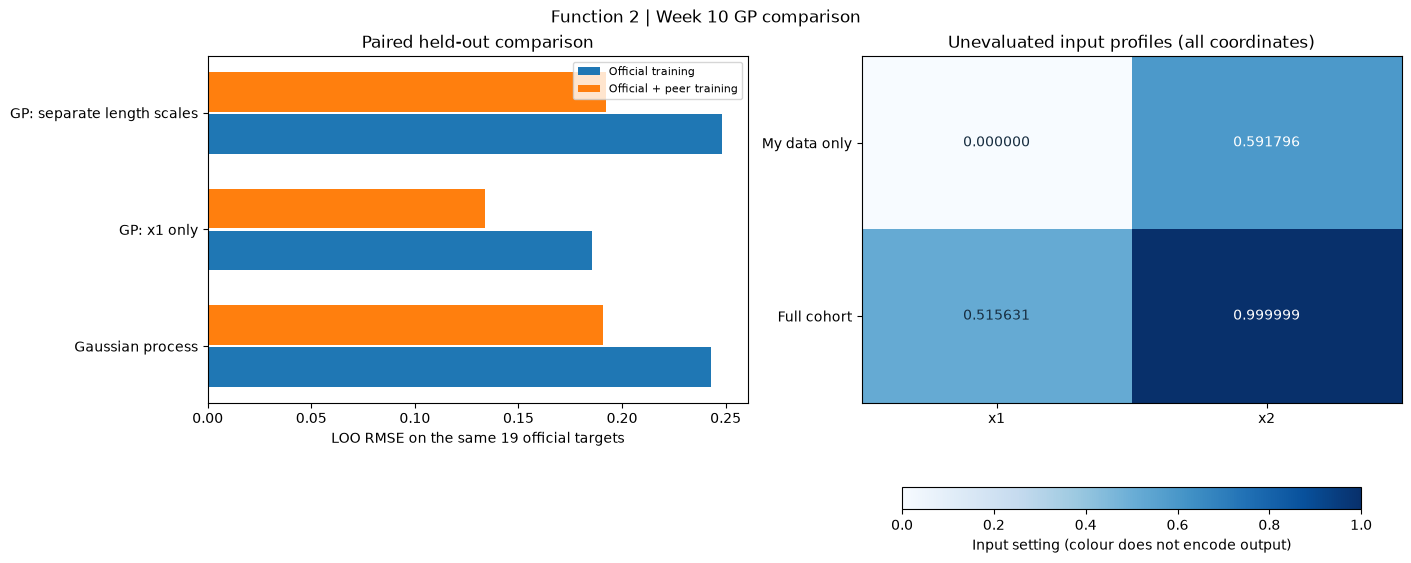

,training_scope,portal_input,nearest_cohort_distance,cohort_eligible,owner_mean,owner_latent_sd,cohort_mean,cohort_latent_sd
0,My data only,0.000000-0.591796,0.132006,True,0.300035,0.285200,0.000764,0.019287
1,Full cohort,0.515631-0.999999,0.182643,True,0.261918,0.278061,0.265617,0.260932


,Weight,x1,x2,Predicted output,Posterior SD
0,0.00,0.706671,0.699218,0.615313,0.008074
1,1.00,0.707100,0.698730,0.615253,0.008200
2,1.96,0.515631,0.999999,0.265617,0.260932
3,3.00,0.516462,0.999999,0.265035,0.261171


In [5]:
display(plot_paired_cohort_profiles(comparison["paired"], {
        "My data only": comparison["owner"]["proposal"]["point"],
        "Full cohort": comparison["cohort"]["proposal"]["point"]},
    input_columns=INPUT_COLUMNS, target_count=intake["official"],
    title=f"Function {FUNCTION_NUMBER} | Week 10 GP comparison",
    error_columns=("Official " + SELECTION_METRIC, "Peer-assisted " + SELECTION_METRIC),
    error_label=SELECTION_METRIC, save_to=FIGURES / "model-scope-comparison.png"))
display(comparison["cross_scores"].drop(columns="point"))
display(comparison["weight_sensitivity"])


In [6]:
summary = {
    "function": FUNCTION_NUMBER, "week": 10, "analysis": "week_10_full_cohort_gp_review",
    "intake_date": "2026-11-25", "target_units": TARGET_LABEL, "metric": SELECTION_METRIC,
    "official_rows": intake["official"], "peer_rows": intake["peer"], "new_peer_rows": intake["new_peer"],
    "official_snapshot_sha256": intake["official_sha256"], "pooled_snapshot_sha256": intake["sha256"],
    "peer_audit_sha256": hashlib.sha256((SNAPSHOT / "dataset-audit.json").read_bytes()).hexdigest(),
    "weekly_model_review_sha256": hashlib.sha256(old_review_path.read_bytes()).hexdigest(),
    "official_target_ids": official_data.observation_id.tolist(),
    "candidate_status": "provisional", "ucb_weight": EXPLORATION_WEIGHT,
    "minimum_query_distance": MIN_QUERY_DISTANCE, "eligible_pool_size": comparison["candidate_count"],
    **{key: comparison[key] for key in ("owner", "cohort", "mean_baseline", "withheld_peer_counts",
                                       "owner_held_out", "cohort_held_out", "warnings")},
    "paired": comparison["paired"].to_dict(orient="records"),
    "cross_scores": comparison["cross_scores"].to_dict(orient="records"),
    "weight_sensitivity": comparison["weight_sensitivity"].to_dict(orient="records"),
}
text = json.dumps(summary, indent=2, allow_nan=False)
(ANALYSIS_DIR / "model-review.json").write_text(text + "\n", encoding="utf-8")
print(text)


{
  "function": 2,
  "week": 10,
  "analysis": "week_10_full_cohort_gp_review",
  "intake_date": "2026-11-25",
  "target_units": "output y",
  "metric": "LOO RMSE",
  "official_rows": 19,
  "peer_rows": 31,
  "new_peer_rows": 4,
  "official_snapshot_sha256": "f752ac1ddab3cd676de50a6a967f272cdbbd915cf4925f27ffbe062d97bf9792",
  "pooled_snapshot_sha256": "a579874c5d0a8f08998c5eaeb9b4e892b59d4563add897ff67435e7d546d69b8",
  "peer_audit_sha256": "7e3f22d716c16da8d012c41b68d367eb8e2689e629e716d3bb175bab80ffdb5c",
  "weekly_model_review_sha256": "805661e83890376fd1114e3d19661f5da46e68b4c939a479be2a96a6d672c52d",
  "official_target_ids": [
    "initial-001",
    "initial-002",
    "initial-003",
    "initial-004",
    "initial-005",
    "initial-006",
    "initial-007",
    "initial-008",
    "initial-009",
    "initial-010",
    "round-01",
    "round-02",
    "round-03",
    "round-04",
    "round-05",
    "round-06",
    "round-07",
    "round-08",
    "round-09"
  ],
  "candidate_status":

## Extended cohort surrogate study

Use the 25 November cohort training pool. Compare the existing GP with other kernels, peer-noise and duplicate-handling variants, a fold-local target transform, ridge with polynomial features or PCA, nearest neighbours, SVR, tree ensembles and a small neural ensemble. The top-quartile logistic and naïve Bayes models convert training-only class probabilities to scores using the two class means. Two local ridge fits use clusters learned from the training inputs. The SVR scaling blend averages fits with standard and robust scaling.

Preprocessing, all fitted parameters and any ensemble choices use their own training folds. An official hold-out also withholds peer observations at the same six-decimal input. The initial screen uses grouped leave-one-out. [Cross-function report](../../../../results/week-10-review.md#pooled-validation-and-tabular-transformer-experiment)

In [7]:
from cohort_surrogate_study import run_cohort_surrogate_study

study = run_cohort_surrogate_study(review, {name: declared[name] for name in GP_NAMES},
    comparison["cohort"]["model"], official_target, peer_target,
    metric=SELECTION_METRIC.removeprefix("LOO "), seeds=(42, 73))
saved_gp = next(row for row in study["fixed_screen"] if row["method"] == study["reference_model"])
np.testing.assert_allclose(saved_gp["error"], comparison["cohort"]["error"], rtol=1e-10, atol=1e-9)
print(f"Completed {study['fit_partitions']} training partitions.")


Completed 69 training partitions.


,Method,RMSE,Error on 8 returned queries,LOO Spearman,Targets closer than saved GP
0,GP Matérn 3/2,0.113550,0.103032,0.842105,11
1,Shallow gradient boosting,0.128511,0.110431,0.819298,8
2,GP higher peer noise,0.129059,0.143470,0.838596,7
3,GP asinh target,0.130884,0.145765,0.880702,7
4,GP median duplicate scores,0.131618,0.149007,0.871930,11
5,GP: x1 only,0.133634,0.150815,0.871930,0
6,Random forest,0.141125,0.110843,0.836842,9
7,Depth-3 regression tree,0.142126,0.144778,0.770175,8
8,GP–SVR–MLP mean,0.144623,0.124782,0.803509,8
9,Top-quartile Gaussian NB,0.157901,0.108114,0.145614,6


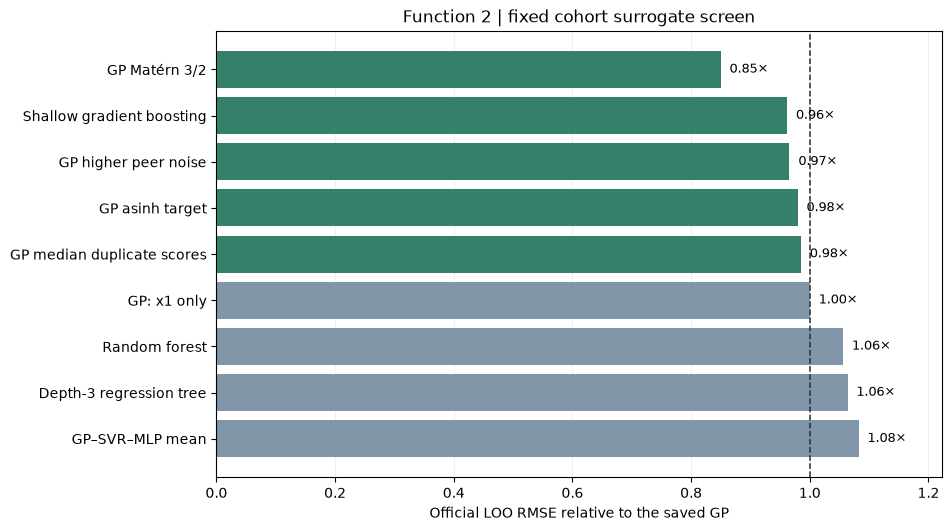

In [8]:
from cohort_surrogate_plots import plot_surrogate_screen

screen = pd.DataFrame(study["fixed_screen"])
display(screen.rename(columns={"method": "Method", "error": study["metric"],
    "returned_error": "Error on 8 returned queries", "rank_correlation": "LOO Spearman",
    "absolute_error_wins": "Targets closer than saved GP"}).round(6))
display(plot_surrogate_screen(study, title=f"Function {FUNCTION_NUMBER} | fixed cohort surrogate screen",
    save_to=FIGURES / "cohort-surrogate-screen.png"))


### Test model choice and blending on outer folds

Repeat five outer folds with two split seeds. Four inner folds select a GP or a method from the full bank. The blended policy chooses a GP, a non-GP partner and a GP weight of 0.25, 0.50 or 0.75 using inner predictions. The nested GP selector can also choose the kernel and data-treatment variants. The saved GP family is refitted on the same outer training data.

The retrospective selection gap is the difference between the best measured score in an outer hold-out shortlist and the score of the point ranked highest by the policy. Smaller is better. This is a check of ranking on measured points. Compare errors within each function because score scales differ.

,policy,mean_error,mean_returned_error,mean_selection_gap,best_picks,seed_42_error,seed_73_error
0,Saved GP family,0.137016,0.157452,0.004019,8,0.137107,0.136926
1,Nested GP selection,0.120510,0.123449,0.000000,10,0.118968,0.122053
2,Nested model selection,0.158563,0.129177,0.000000,10,0.154870,0.162256
3,Nested GP blend,0.132927,0.110831,0.000000,10,0.130024,0.135830


,Split seed,Outer fold,GP family or variant,Selected model,Blend partner,GP blend weight,Matching peer rows withheld
0,42,1,GP higher peer noise,GP higher peer noise,Shallow gradient boosting,0.75,0
1,42,2,GP higher peer noise,GP higher peer noise,Top-quartile Gaussian NB,0.50,2
2,42,3,GP Matérn 3/2,GP Matérn 3/2,Depth-3 regression tree,0.75,0
3,42,4,GP higher peer noise,Random forest,Random forest,0.25,0
4,42,5,GP higher peer noise,GP higher peer noise,Depth-3 regression tree,0.75,0
5,73,1,GP higher peer noise,GP higher peer noise,Depth-3 regression tree,0.75,0
6,73,2,GP Matérn 3/2,Top-quartile Gaussian NB,Top-quartile Gaussian NB,0.50,2
7,73,3,GP Matérn 3/2,Random forest,Random forest,0.50,0
8,73,4,GP Matérn 3/2,GP Matérn 3/2,Depth-3 regression tree,0.50,0
9,73,5,GP higher peer noise,GP higher peer noise,Top-quartile Gaussian NB,0.75,0


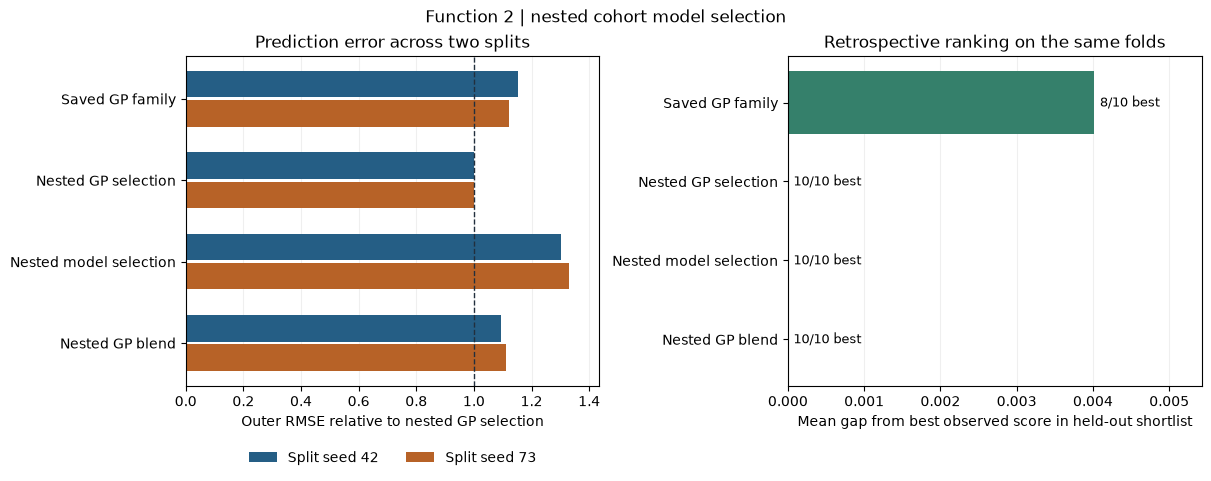

In [9]:
from cohort_surrogate_study import nested_summary
from cohort_surrogate_plots import plot_nested_comparison

summary_table = nested_summary(study)
display(summary_table.round(6))
choices = pd.DataFrame([
    {"Split seed": repeat["seed"], "Outer fold": fold["fold"], "GP family or variant": fold["selected_gp"],
     "Selected model": fold["selected_model"], "Blend partner": fold["blend_alternate"],
     "GP blend weight": fold["gp_weight"], "Matching peer rows withheld": fold["peer_rows_withheld"]}
    for repeat in study["nested"] for fold in repeat["folds"]
])
display(choices)
display(plot_nested_comparison(study, title=f"Function {FUNCTION_NUMBER} | nested cohort model selection",
    save_to=FIGURES / "cohort-nested-validation.png"))


In [10]:
study.update(function=FUNCTION_NUMBER, week=10, intake_date="2026-11-25",
    target_units=TARGET_LABEL, official_rows=intake["official"], peer_rows=intake["peer"],
    official_snapshot_sha256=intake["official_sha256"], pooled_snapshot_sha256=intake["sha256"],
    gp_comparison_sha256=hashlib.sha256((ANALYSIS_DIR / "model-review.json").read_bytes()).hexdigest(),
    selection_gap_units=TARGET_LABEL, outer_seed=[42, 73],
    nested_summary=summary_table.to_dict(orient="records"))
payload = json.dumps(study, indent=2, allow_nan=False)
(ANALYSIS_DIR / "surrogate-study.json").write_text(payload + "\n", encoding="utf-8")
print("Saved fold choices, predictions, warnings and input fingerprints to surrogate-study.json.")


Saved fold choices, predictions, warnings and input fingerprints to surrogate-study.json.


## Small tabular transformer experiment

Each numeric coordinate becomes its own feature token. A single frozen block applies scaled dot-product self-attention and a residual feed-forward layer. Feature representations are fixed by three seeds. A ridge readout and its scaler are fitted only on the training partition. The same random tokeniser, feed-forward layer and readout are used in the attention-off ablation. This tests the value of the attention features, with the saved GP on the identical portal-grouped official holdouts. Peers at each held-out portal input are withheld. The experiment does not estimate acquisition uncertainty or select a query. [Tabular feature-tokenisation reference](https://proceedings.neurips.cc/paper_files/paper/2021/hash/9d86d83f925f2149e9edb0ac3b49229c-Abstract.html)

In [11]:
from cohort_attention import compare_cohort_attention

attention = compare_cohort_attention(review, peer_target, study)
attention.update(function=FUNCTION_NUMBER, week=10, target_units=TARGET_LABEL,
    official_snapshot_sha256=intake["official_sha256"], pooled_snapshot_sha256=intake["sha256"])
display(pd.DataFrame(attention["results"]).drop(columns="predictions").set_index("method").round(6))
(ANALYSIS_DIR / "attention-study.json").write_text(
    json.dumps(attention, indent=2, allow_nan=False) + "\n", encoding="utf-8")

,error,returned_error
method,,
GP: x1 only,0.133634,0.150815
Frozen transformer + ridge,0.179897,0.151750
No-attention tokens + ridge,0.154847,0.127935


2601

### Interpreting the comparison

Compare later-return error with the fixed screen and outer-fold shortlist results. The shortlist tests ranking on held-out observations. A proposed input is still unmeasured.

## Course lifecycle

1. **Define the goal and scope** — compare provisional Week 10 GP query suggestions across two training scopes and test alternative cohort surrogates.
2. **Gather the data** — use the Week 10 official observations and the 25 November published peer returns.
3. **Explore the data** — compare score distributions, measured ranks, official progress and input profiles in the companion notebook.
4. **Clean and preprocess the data** — validate checksums, dimensions, bounds and finite values. Match duplicates at six-decimal portal precision and fit scalers and target transforms within each training fold.
5. **Select and engineer features** — use the declared coordinates and GP feature subsets, and compare quadratic and PCA features with ridge.
6. **Define the machine-learning task** — regress a continuous score for bounded black-box maximisation.
7. **Partition the data** — use grouped leave-one-out and repeated nested folds on official targets. Withhold matching peers for all omitted official inputs.
8. **Select and train candidate methods** — fit the established GPs per scope, and test the declared alternative surrogates and blends on the cohort pool.
9. **Evaluate and interpret the results** — compare held-out errors, candidate scores and UCB weight sensitivity. Use outer-fold predictions to assess model choice and blending.
10. **Deploy and iterate** — deployment is not applicable. Save provisional inputs and revisit the evidence after the next return.
